# 2D Shin–Metiu TGIFS with optional photon qumode

The molecular Hamiltonian remains **nonharmonic**: kinetic energy is implemented by Gaussian free-particle gates, and the full Shin–Metiu potential is implemented by TGIFS Fourier gates.

Set `include_cavity=False` for the original two-qumode calculation. Setting `include_cavity=True` introduces one photon qumode and implements the single-mode cavity Hamiltonian of Eqs. (3)–(4) in Lacombe, Hoffmann & Maitra, *PRL* **123**, 083201 (2019):

$$
H=\frac{p_r^2}{2m_e}+\frac{P_R^2}{2M}+V_{\rm SM}(r,R)+\omega_\alpha(b^\dagger b+1/2)
+\lambda_\alpha\sqrt{\omega_\alpha}\,X_\alpha(R-r)
+\frac{\lambda_\alpha^2}{2}(R-r)^2.
$$

The last (dipole self-energy) term has its own switch. Photon–matter coupling uses two Gaussian `cv_sum` operations and photon rotations; no 3D Fourier fitting is needed. The photon begins in vacuum.

**Memory choices:** Reuse identical `cv_c_d` gate objects within the step circuit, store observables at **every** output time, and save **normalized ancilla-|0> wavefunction snapshots** only every `N_save` points (plus the last point if requested). The snapshot array has shape `(n_saved, cutoff_r, cutoff_R)` without a cavity or `(n_saved, cutoff_ph, cutoff_r, cutoff_R)` with a cavity. Recorded snapshot indices and times disambiguate the sparse time grid.

`RUN_CPU_BASELINES=False` by default avoids building the large cavity-free CPU Hamiltonians in this notebook. They can be enabled for a cavity-free cross-check, but are **not cavity-coupled CPU references** when `include_cavity=True`.


In [3]:
import math
import csv
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from numpy.polynomial.hermite import hermgauss
from scipy.linalg import eigh, expm
from scipy.special import erf, eval_hermite, factorial

import qiskit
import bosonic_qiskit
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector


## Parameters

In [19]:
# Atomic units
hbar = 1.0
me = 1.0
M = 1836.0

# Shin–Metiu molecular potential
L_SM = 19.0
Z_nuc = 1.0
Rl = 3.1
Rr = 4.0
Rf = 5.0

# These frequencies define the coordinate/Fock scales ONLY.
r0 = 0.0
R0 = 0.0
omega = 0.025
Omega = 0.0025
l_r = np.sqrt(hbar / (me * omega))
l_R = np.sqrt(hbar / (M * Omega))

# CPU/Fock basis sizes
Nr = 16
NR = 128
Nquad_r = 200
Nquad_R = 200

# The original Fourier fit settings
FOURIER_BOX = (40.0, 80.0)  # (box_R, box_r) physical a.u.
FOURIER_ORDER = (14, 14)      # limits are exclusive
FOURIER_BASIS = 'half_lattice'
RIDGE_LAMBDA = 1e-4
ORDER_WEIGHT_STRENGTH = 10.0
ORDER_WEIGHT_POWER = 1.0

# Optional sparse fit; None reproduces original dense ridge fit.
# For the sparse workflow use TOP_N_MODES = 20, etc.
TOP_N_MODES = 30 #None
TOP_N_SELECTION = 'force_scale'  # 'amplitude' or 'force_scale'
REFIT_RIDGE_MULTIPLIER = 1.0

# 'internal': run ridge fit (and optional top-N/refit)
# 'csv'/'txt': load preselected Fourier support and coefficients
FIT_SOURCE = 'internal'
FIT_PARAMETER_FILE = Path('sample_selected_fit.csv')

r_surface = np.arange(-30.0, 30.0, 1.0)
R_surface = np.arange(-6.0, 6.0, 1.0)

times = np.linspace(0.0, 1400.0, 71)
AU_TIME_TO_FS = 0.024188843265857

NUM_QUBITS_r = int(np.ceil(np.log2(Nr)))
NUM_QUBITS_R = int(np.ceil(np.log2(NR)))
CUTOFF_r = 2**NUM_QUBITS_r
CUTOFF_R = 2**NUM_QUBITS_R

# -------------------------------------------------------------
# Cavity switches and physical parameters from Eqs. (3)–(4)
# -------------------------------------------------------------
include_cavity = False  # False: original two-qumode TGIFS algorithm
include_dipole_self_energy = True
omega_alpha = 0.1
lambda_alpha = 0.005
NUM_QUBITS_ph = 1                 # cutoff = 8 photon Fock states
CUTOFF_ph = 2**NUM_QUBITS_ph if include_cavity else 1

# TGIFS/Strang propagation
TGIFS_SUBSTEPS = 20
KINETIC_IMPLEMENTATION = 'gaussian'  # or 'matrix' (debug only)
COEFF_TOL = 1e-12

# -------------------------------------------------------------
# Memory control
# -------------------------------------------------------------
N_save = 10                       # save snapshots at indices 0,10,20,...
SAVE_LAST_WAVEFUNCTION = True     # additionally save last output point
RUN_CPU_BASELINES = True        # avoids CPU dense eigensolvers in this run

RESULTS_DIR = Path('tgifs_full_potential_results')
RESULTS_DIR.mkdir(exist_ok=True)

if N_save is not None and int(N_save) < 1:
    raise ValueError('N_save must be a positive integer or None to disable snapshots')
if TGIFS_SUBSTEPS < 1:
    raise ValueError('TGIFS_SUBSTEPS must be positive')
if include_cavity and omega_alpha <= 0:
    raise ValueError('omega_alpha must be positive')

TGIFS_DT_FOR_DIAGNOSTICS = (times[1] - times[0]) / TGIFS_SUBSTEPS

print('Coordinate lengths l_r, l_R:', l_r, l_R)
print('Fock cutoffs r, R, ph:', CUTOFF_r, CUTOFF_R, CUTOFF_ph)
print('include_cavity =', include_cavity)
print('include_dipole_self_energy =', include_cavity and include_dipole_self_energy)
print('CPU baselines in this notebook =', RUN_CPU_BASELINES)


Coordinate lengths l_r, l_R: 6.324555320336759 0.46676002800933664
Fock cutoffs r, R, ph: 16 128 1
include_cavity = False
include_dipole_self_energy = False
CPU baselines in this notebook = True


## Full Shin–Metiu potential

In [20]:
def erf_coulomb(x, sigma):
    x = np.asarray(x)
    ax = np.abs(x)
    out = np.empty_like(ax, dtype=float)
    mask = ax > 1e-12
    out[mask] = erf(ax[mask] / sigma) / ax[mask]
    out[~mask] = 2.0 / (np.sqrt(np.pi) * sigma)
    return out


def V_SM(r, R):
    V_nn = (
        Z_nuc**2 / np.abs(R - L_SM / 2.0)
        + Z_nuc**2 / np.abs(R + L_SM / 2.0)
    )

    V_e_mobile = -Z_nuc * erf_coulomb(r - R, Rf)
    V_e_right = -Z_nuc * erf_coulomb(r - L_SM / 2.0, Rr)
    V_e_left = -Z_nuc * erf_coulomb(r + L_SM / 2.0, Rl)

    return V_nn + V_e_mobile + V_e_right + V_e_left

## Fourier fit of the full potential

The fit is

$$
V_{\rm fit}(R,r)=C_0+\sum_\mu
A_\mu\cos(\mu_RR+\mu_rr)+
B_\mu\sin(\mu_RR+\mu_rr).
$$

`C0` is retained in the classical fitted baseline.  It is not needed in the TGIFS circuit because it only changes the global phase.

In [21]:
def normalize_order(order):
    if np.isscalar(order):
        return (int(order), int(order))
    return (int(order[0]), int(order[1]))


def build_mvec(NF, basis='positive_only'):
    NF_R, NF_r = normalize_order(NF)

    if basis == 'positive_only':
        return np.array([
            [mR, mr]
            for mR in range(NF_R)
            for mr in range(NF_r)
            if mR > 0 or mr > 0
        ], dtype=int)

    if basis == 'half_lattice':
        modes = []
        for mR in range(NF_R):
            if mR == 0:
                for mr in range(1, NF_r):
                    modes.append([0, mr])
            else:
                for mr in range(-(NF_r - 1), NF_r):
                    modes.append([mR, mr])
        return np.asarray(modes, dtype=int)

    raise ValueError('Unknown Fourier basis')


def fit_fourier_full_V(fourier_box, NF, basis=FOURIER_BASIS):
    fourier_box = np.asarray(fourier_box, dtype=float)
    mvec = build_mvec(NF, basis=basis)

    r_mesh, R_mesh = np.meshgrid(r_surface, R_surface, indexing='xy')
    target = V_SM(r_mesh, R_mesh).ravel()

    # Columns: physical wavevector multiplying [R, r]
    mu_phys = mvec * (2.0 * np.pi / fourier_box)[None, :]

    phase = (
        R_mesh.ravel()[:, None] * mu_phys[None, :, 0]
        + r_mesh.ravel()[:, None] * mu_phys[None, :, 1]
    )


    # Include a constant coefficient explicitly.
    design = np.concatenate([
        np.ones((target.size, 1)),
        np.cos(phase),
        np.sin(phase),
    ], axis=1)

    pars, *_ = np.linalg.lstsq(design, target, rcond=None)

    nmode = len(mvec)
    C0 = pars[0]
    A = pars[1:1+nmode]
    B = pars[1+nmode:]
    #C0=0
    #A = pars[0:nmode]
    #B = pars[nmode:]

    residual = design @ pars - target

    return {
        'fourier_box': fourier_box,
        'NF': np.asarray(normalize_order(NF), dtype=int),
        'mvec': mvec,
        'mu_phys': mu_phys,
        'C0': float(C0),
        'A': A,
        'B': B,
        'pars':pars,
        'rmse': float(np.sqrt(np.mean(residual**2))),
        'max_abs_error': float(np.max(np.abs(residual))),
        'design_condition': float(np.linalg.cond(design)),
    }


def evaluate_fourier_full_V(r, R, fit):
    rvals = np.asarray(r).ravel()
    Rvals = np.asarray(R).ravel()
    r_eval, R_eval = np.meshgrid(rvals, Rvals, indexing='ij')

    phase = (
        R_eval.ravel()[:, None] * fit['mu_phys'][None, :, 0]
        + r_eval.ravel()[:, None] * fit['mu_phys'][None, :, 1]
    )

    values = (
        fit['C0']
        + np.cos(phase) @ fit['A']
        + np.sin(phase) @ fit['B']
    )

    return values.reshape(rvals.size, Rvals.size)

def order_weights(mvec, NF, strength=ORDER_WEIGHT_STRENGTH, power=ORDER_WEIGHT_POWER):
    NF_R, NF_r = normalize_order(NF)

    scale_R = max(NF_R - 1, 1)
    scale_r = max(NF_r - 1, 1)

    order2 = (
        (mvec[:, 0] / scale_R)**2
        + (mvec[:, 1] / scale_r)**2
    )

    order_norm = np.sqrt(order2)
    weights = 1.0 + strength * order2**power

    return weights, order_norm


def fit_fourier_full_V_ridge(
    fourier_box,
    NF,
    basis=FOURIER_BASIS,
    ridge_lambda=RIDGE_LAMBDA,
    order_strength=ORDER_WEIGHT_STRENGTH,
    order_power=ORDER_WEIGHT_POWER,
):
    fourier_box = np.asarray(fourier_box, dtype=float)
    NF = normalize_order(NF)
    mvec = build_mvec(NF, basis=basis)
    #mvec = build_half_lattice(NF)

    r_mesh, R_mesh = np.meshgrid(r_surface, R_surface, indexing='xy')
    target = V_SM(r_mesh, R_mesh).ravel()

    # Physical Fourier wavevectors: columns multiply [R, r].
    mu_phys = mvec * (2.0 * np.pi / fourier_box)[None, :]

    phase = (
        R_mesh.ravel()[:, None] * mu_phys[None, :, 0]
        + r_mesh.ravel()[:, None] * mu_phys[None, :, 1]
    )

    design = np.concatenate([
        np.ones((target.size, 1)),
        np.cos(phase),
        np.sin(phase),
    ], axis=1)

    nmode = len(mvec)
    mode_weight, order_norm = order_weights(
        mvec,
        NF,
        strength=order_strength,
        power=order_power,
    )

    # C0 is unpenalized. A_mu and B_mu receive identical weights.
    penalty = np.concatenate([
        [0.0],
        mode_weight,
        mode_weight,
    ])

    reg_matrix = np.diag(np.sqrt(ridge_lambda * penalty))

    design_aug = np.vstack([design, reg_matrix])
    target_aug = np.concatenate([target, np.zeros(design.shape[1])])

    pars, *_ = np.linalg.lstsq(design_aug, target_aug, rcond=None)

    C0 = pars[0]
    A = pars[1:1 + nmode]
    B = pars[1 + nmode:]

    prediction = design @ pars
    residual = prediction - target

    amplitude = np.sqrt(A**2 + B**2)
    amp2 = amplitude**2
    if np.sum(amp2) > 0.0:
        mode_probability = amp2 / np.sum(amp2)
    else:
        mode_probability = np.zeros_like(amplitude)

    # Coordinate-scaled wavevectors useful for TGIFS diagnostics.
    mu_dimless = mu_phys * np.array([l_R, l_r])[None, :]
    kappa = 0.5 * mu_dimless
    kappa_norm = np.linalg.norm(kappa, axis=1)

    theta_A = 0.5 * TGIFS_DT_FOR_DIAGNOSTICS * np.abs(A)
    theta_B = 0.5 * TGIFS_DT_FOR_DIAGNOSTICS * np.abs(B)

    return {
        'fourier_box': fourier_box,
        'NF': np.asarray(NF, dtype=int),
        'mvec': mvec,
        'mu_phys': mu_phys,
        'mu_dimless': mu_dimless,
        'kappa': kappa,
        'kappa_norm': kappa_norm,
        'C0': float(C0),
        'A': A,
        'B': B,
        'amplitude': amplitude,
        'mode_probability': mode_probability,
        'order_norm': order_norm,
        'mode_weight': mode_weight,
        'ridge_lambda': float(ridge_lambda),
        'order_strength': float(order_strength),
        'order_power': float(order_power),
        'rmse': float(np.sqrt(np.mean(residual**2))),
        'max_abs_error': float(np.max(np.abs(residual))),
        'design_condition': float(np.linalg.cond(design)),
        'regularized_condition': float(np.linalg.cond(design_aug)),
        'theta_max_A': float(np.max(theta_A)),
        'theta_max_B': float(np.max(theta_B)),
    }




def _fit_ridge_on_selected_support(
    mvec, mu_phys, NF, ridge_lambda, order_strength, order_power
):
    """Same weighted-ridge penalty as the original fit, restricted to a support."""
    rmesh, Rmesh = np.meshgrid(r_surface, R_surface, indexing='xy')
    y = V_SM(rmesh, Rmesh).ravel()
    phase = (
        Rmesh.ravel()[:, None] * mu_phys[None, :, 0]
        + rmesh.ravel()[:, None] * mu_phys[None, :, 1]
    )
    D = np.column_stack([np.ones(len(y)), np.cos(phase), np.sin(phase)])
    mode_weight, _ = order_weights(
        mvec, NF, strength=order_strength, power=order_power
    )
    penalty = np.r_[0., mode_weight, mode_weight]
    Daug = np.vstack([D, np.diag(np.sqrt(ridge_lambda * penalty))])
    yaug = np.r_[y, np.zeros(D.shape[1])]
    pars, *_ = np.linalg.lstsq(Daug, yaug, rcond=None)
    n = len(mvec)
    return float(pars[0]), pars[1:1+n], pars[1+n:], float(np.sqrt(np.mean((D @ pars-y)**2)))


def make_sparse_fit(raw_fit, top_n, method=TOP_N_SELECTION):
    amplitude = np.hypot(raw_fit['A'], raw_fit['B'])
    if method == 'amplitude':
        score = amplitude
    elif method == 'force_scale':
        score = amplitude * np.linalg.norm(raw_fit['mu_phys'], axis=1)
    else:
        raise ValueError("TOP_N_SELECTION must be 'amplitude' or 'force_scale'")
    n = min(int(top_n), len(score))
    if n < 1:
        raise ValueError('TOP_N_MODES must be positive')
    idx = np.argsort(score)[-n:]
    idx = idx[np.argsort(score[idx])[::-1]]
    mvec = raw_fit['mvec'][idx]
    mu = raw_fit['mu_phys'][idx]
    refit_lambda = REFIT_RIDGE_MULTIPLIER * RIDGE_LAMBDA
    C0, A, B, rmse = _fit_ridge_on_selected_support(
        mvec, mu, raw_fit['NF'], refit_lambda,
        ORDER_WEIGHT_STRENGTH, ORDER_WEIGHT_POWER
    )
    sparse = dict(raw_fit)
    sparse.update(mvec=mvec, mu_phys=mu, C0=C0, A=A, B=B, rmse=rmse)
    return sparse


def load_fit_file(path):
    """Read # key=value metadata plus CSV or whitespace mR,mr,A,B columns."""
    path = Path(path)
    metadata, rows = {}, []
    for raw in path.read_text().splitlines():
        line = raw.strip()
        if line.startswith('#'):
            part = line[1:].strip()
            if '=' in part:
                k, v = part.split('=', 1)
                metadata[k.strip()] = v.strip()
        elif line:
            rows.append(line)
    if len(rows) < 2:
        raise ValueError('File needs a header and at least one coefficient row')
    if path.suffix.lower() == '.csv':
        records = list(csv.DictReader(rows))
    elif path.suffix.lower() == '.txt':
        fields = rows[0].split()
        records = [dict(zip(fields, line.split())) for line in rows[1:]]
    else:
        raise ValueError('Supported file types are CSV and TXT')
    if not {'mR', 'mr', 'A', 'B'} <= set(records[0]):
        raise ValueError('Required columns: mR, mr, A, B')
    mvec = np.asarray([[int(float(x['mR'])), int(float(x['mr']))] for x in records], int)
    A = np.asarray([float(x['A']) for x in records])
    B = np.asarray([float(x['B']) for x in records])
    box = np.asarray([
        float(metadata.get('fourier_box_R', FOURIER_BOX[0])),
        float(metadata.get('fourier_box_r', FOURIER_BOX[1])),
    ])
    NF = np.asarray([
        int(float(metadata.get('NF_R', FOURIER_ORDER[0]))),
        int(float(metadata.get('NF_r', FOURIER_ORDER[1]))),
    ])
    mu = mvec * (2*np.pi/box)[None,:]
    return {
        'mvec': mvec, 'mu_phys': mu, 'A': A, 'B': B,
        'C0': float(metadata.get('C0', 0.0)),
        'fourier_box': box, 'NF': NF,
    }


def export_fit_file(fit, path):
    """Save selected coefficients in the same CSV/TXT format the loader accepts."""
    path = Path(path)
    box = fit['fourier_box']
    nf = fit['NF']
    header = (f'# fourier_box_R={box[0]}\n# fourier_box_r={box[1]}\n'
              f'# NF_R={nf[0]}\n# NF_r={nf[1]}\n# C0={fit["C0"]}\n')
    with path.open('w') as f:
        f.write(header)
        if path.suffix.lower() == '.csv':
            w = csv.writer(f)
            w.writerow(['mR','mr','A','B'])
            for mode,a,b in zip(fit['mvec'],fit['A'],fit['B']):
                w.writerow([int(mode[0]),int(mode[1]),repr(float(a)),repr(float(b))])
        elif path.suffix.lower() == '.txt':
            f.write('mR mr A B\n')
            for mode,a,b in zip(fit['mvec'],fit['A'],fit['B']):
                f.write(f'{mode[0]} {mode[1]} {a:.17g} {b:.17g}\n')
        else:
            raise ValueError('Supported file types are CSV and TXT')


if FIT_SOURCE == 'internal':
    fit = fit_fourier_full_V_ridge(FOURIER_BOX, FOURIER_ORDER)
    if TOP_N_MODES is not None:
        fit = make_sparse_fit(fit, TOP_N_MODES)
elif FIT_SOURCE in ('csv', 'txt'):
    fit = load_fit_file(FIT_PARAMETER_FILE)
else:
    raise ValueError("FIT_SOURCE must be 'internal', 'csv' or 'txt'")

# Reconstruct all derived quantities from the *retained* support. The raw
# ridge fit may have had more modes, so never reuse its old kappa/amplitude.
fit['amplitude'] = np.hypot(fit['A'], fit['B'])
fit['mu_dimless'] = fit['mu_phys'] * np.array([l_R, l_r])[None, :]
fit['kappa'] = 0.5 * fit['mu_dimless']

# The digest keeps loaded/refitted sparse fits from reusing wrong trajectories.
_digest = hashlib.blake2b(digest_size=8)
for key in ['mu_phys', 'A', 'B']:
    _digest.update(np.asarray(fit[key], dtype=np.float64).tobytes())
_digest.update(np.float64(fit['C0']).tobytes())
FIT_DIGEST = _digest.hexdigest()
print('Fourier modes retained:', len(fit['A']))
print('Fit digest:', FIT_DIGEST)
print('Coefficient maximum:', np.max(np.hypot(fit['A'], fit['B'])))


Fourier modes retained: 30
Fit digest: be365c189d264200
Coefficient maximum: 0.18310618065119563


## Initial product state in the same Fock basis

In [7]:
# Sinc-DVR only to obtain the second BO electronic state at R=-4.
n_dvr = 150
dx = 18.5 / n_dvr
r_dvr = np.array([i * dx for i in range(-n_dvr, n_dvr + 1)])

d2xmat = np.array([
    [
        -np.pi**2 / (3.0 * dx**2)
        if i == j
        else -2.0 * (-1)**(i - j) / (dx * (i - j))**2
        for j in range(-n_dvr, n_dvr + 1)
    ]
    for i in range(-n_dvr, n_dvr + 1)
])


def electronic_hamiltonian(R_value):
    return -0.5 * d2xmat + np.diag(V_SM(r_dvr, R_value))


_, eigvec_e = eigh(electronic_hamiltonian(-4.0))
psi0_e = eigvec_e[:, 1]


def ho_basis_realspace(N, q, q0, l):
    x = (q - q0) / l
    phi = np.zeros((N, len(q)))
    for n in range(N):
        norm = np.pi**(-0.25) / (np.sqrt(l) * np.sqrt(2.0**n * factorial(n)))
        phi[n] = norm * eval_hermite(n, x) * np.exp(-x**2 / 2.0)
    return phi


def initial_fock_coefficients(Nr_basis=Nr, NR_basis=NR):
    psi_e = psi0_e.astype(complex).copy()
    psi_e /= np.sqrt(np.trapezoid(np.abs(psi_e)**2, r_dvr))
    phi_r = ho_basis_realspace(Nr_basis, r_dvr, r0, l_r)
    c_e = np.array([
        np.trapezoid(np.conj(phi_r[n]) * psi_e, r_dvr)
        for n in range(Nr_basis)
    ], dtype=complex)

    R_grid = np.linspace(-15.0, 15.0, 4000)
    psi_R = np.exp(-2.85 * (R_grid + 4.0)**2)
    psi_R /= np.sqrt(np.trapezoid(np.abs(psi_R)**2, R_grid))
    phi_R = ho_basis_realspace(NR_basis, R_grid, R0, l_R)
    c_R = np.array([
        np.trapezoid(np.conj(phi_R[n]) * psi_R, R_grid)
        for n in range(NR_basis)
    ], dtype=complex)

    captured_e = np.sum(np.abs(c_e)**2)
    captured_R = np.sum(np.abs(c_R)**2)

    c_e /= np.linalg.norm(c_e)
    c_R /= np.linalg.norm(c_R)

    return c_e, c_R, captured_e, captured_R


c_e_cpu, c_R_cpu, cap_e, cap_R = initial_fock_coefficients()
psi0_cpu = np.outer(c_e_cpu, c_R_cpu).ravel()

print('captured initial norm: electron =', cap_e, ', nucleus =', cap_R)

captured initial norm: electron = 0.9974529177722165 , nucleus = 1.0000000000000104


## CPU baselines without harmonic separation

In the scaled Fock basis,

$$
p=\frac{\hbar}{l}P,
\qquad
T=\frac{\hbar^2}{2ml^2}P^2.
$$

The potential matrix elements are evaluated numerically in physical coordinates.  Thus both CPU Hamiltonians have the form

$$
H=T_r+T_R+V,
$$

with either exact $V_{\rm SM}$ or the full Fourier fit.

In [22]:
from scipy.sparse.linalg import LinearOperator, expm_multiply

# 'exact' uses the original non-fitted Shin-Metiu PES.
# Add 'fit' to also calculate the Fourier-fitted CPU reference.
CPU_BASELINE_POTENTIALS = ('exact','fit')


# ============================================================
# Fock-basis operators
# ============================================================

def X_fock(N):
    X = np.zeros((N, N), dtype=float)

    for n in range(N - 1):
        x = np.sqrt(n + 1.0) / np.sqrt(2.0)
        X[n, n + 1] = x
        X[n + 1, n] = x

    return X


def P_fock(N):
    P = np.zeros((N, N), dtype=complex)

    for n in range(N - 1):
        p = np.sqrt(n + 1.0) / np.sqrt(2.0)
        P[n, n + 1] = -1j * p
        P[n + 1, n] = +1j * p

    return P


def kinetic_1d(N, mass, length):
    P = P_fock(N)

    return np.asarray(
        (
            hbar**2 / (2.0 * mass * length**2)
            * (P @ P)
        ).real,
        dtype=float
    )


# ============================================================
# Gauss-Hermite integration of the original PES
# ============================================================

def ho_polynomials(N, x):
    return np.array([
        np.pi**(-0.25)
        * eval_hermite(n, x)
        / np.sqrt(2.0**n * factorial(n))
        for n in range(N)
    ])


xr, wr = hermgauss(Nquad_r)
xR, wR = hermgauss(Nquad_R)

r_quad = r0 + l_r * xr
R_quad = R0 + l_R * xR

Br_quad = (
    ho_polynomials(Nr, xr)
    * np.sqrt(wr)[None, :]
)

BR_quad = (
    ho_polynomials(NR, xR)
    * np.sqrt(wR)[None, :]
)


def potential_matrix(potential_function):

    values = potential_function(
        r_quad[:, None],
        R_quad[None, :]
    )

    if values.shape != (Nquad_r, Nquad_R):
        raise ValueError(
            "Incorrect potential grid shape: "
            + repr(values.shape)
        )

    out = np.einsum(
        'ni,mi,aj,bj,ij->namb',
        Br_quad,
        Br_quad,
        BR_quad,
        BR_quad,
        values,
        optimize=True
    )

    return np.asarray(
        out.reshape(Nr * NR, Nr * NR),
        dtype=float
    )


# ============================================================
# Molecular operators
# ============================================================

Tr = kinetic_1d(Nr, me, l_r)
TR = kinetic_1d(NR, M, l_R)

r_op = (
    r0 * np.eye(Nr)
    + l_r * X_fock(Nr)
)

R_op = (
    R0 * np.eye(NR)
    + l_R * X_fock(NR)
)

r_op2 = r_op @ r_op
R_op2 = R_op @ R_op


# ============================================================
# Photon operators
# ============================================================

Nph_cpu = CUTOFF_ph if include_cavity else 1

Xph = (
    X_fock(Nph_cpu)
    if include_cavity
    else np.zeros((1, 1))
)

Eph = (
    omega_alpha * (np.arange(Nph_cpu) + 0.5)
    if include_cavity
    else np.zeros(1)
)


# ============================================================
# Matrix-free Hamiltonian
# ============================================================

def make_cpu_hamiltonian(Vmat):
    """
    Return H.matvec and Tr(H) without constructing
    the complete three-mode Hamiltonian matrix.
    """

    Vmat = np.asarray(Vmat, dtype=float)

    coupling = (
        lambda_alpha * np.sqrt(omega_alpha)
        if include_cavity
        else 0.0
    )

    dse_strength = (
        0.5 * lambda_alpha**2
        if include_cavity and include_dipole_self_energy
        else 0.0
    )

    def dipole_action(u):
        # u[nr,nR]
        # D = R-r, using physical coordinate operators

        return (
            u @ R_op.T
            - r_op @ u
        )

    def dipole_squared_action(u):
        # (R-r)^2

        return (
            u @ R_op2.T
            + r_op2 @ u
            - 2.0 * (r_op @ u @ R_op.T)
        )

    def H_dot(v):

        psi = np.asarray(
            v,
            dtype=complex
        ).reshape(Nph_cpu, Nr, NR)

        out = np.empty_like(psi)

        dpsi = (
            np.empty_like(psi)
            if include_cavity
            else None
        )

        for nph in range(Nph_cpu):

            u = psi[nph]

            # Matter kinetic energy + exact molecular PES
            # + free photon energy

            out[nph] = (
                Tr @ u
                + u @ TR.T
                + (
                    Vmat @ u.reshape(-1)
                ).reshape(Nr, NR)
                + Eph[nph] * u
            )

            if include_cavity:

                dpsi[nph] = dipole_action(u)

                # Dipole self-energy
                if dse_strength:
                    out[nph] += (
                        dse_strength
                        * dipole_squared_action(u)
                    )

        # Linear photon-matter coupling
        if include_cavity:

            out += (
                coupling
                * (
                    Xph @ dpsi.reshape(Nph_cpu, -1)
                ).reshape(Nph_cpu, Nr, NR)
            )

        return out.reshape(-1)

    # Trace for scipy.sparse.linalg.expm_multiply.
    # The photon-matter coupling has zero trace.

    trace_matter = (
        NR * np.trace(Tr)
        + Nr * np.trace(TR)
        + np.trace(Vmat)
    )

    trace_d2 = (
        Nr * np.trace(R_op2)
        + NR * np.trace(r_op2)
        - 2.0 * np.trace(R_op) * np.trace(r_op)
    )

    trace_H = (
        Nph_cpu * (
            trace_matter
            + dse_strength * trace_d2
        )
        + Nr * NR * np.sum(Eph)
    )

    return H_dot, float(np.real(trace_H))


# ============================================================
# Expectation values
# ============================================================

def cpu_cavity_moments(psi):
    """
    psi[nph, nr, nR]

    No ancilla postselection is needed for CPU evolution.
    """

    mean_r = np.einsum(
        'pra,rs,psa->',
        psi.conj(),
        r_op,
        psi
    ).real

    mean_r2 = np.einsum(
        'pra,rs,psa->',
        psi.conj(),
        r_op2,
        psi
    ).real

    mean_R = np.einsum(
        'pra,ab,prb->',
        psi.conj(),
        R_op,
        psi
    ).real

    mean_R2 = np.einsum(
        'pra,ab,prb->',
        psi.conj(),
        R_op2,
        psi
    ).real

    pop_ph = np.sum(
        np.abs(psi)**2,
        axis=(1, 2)
    )

    return {
        'mean_r': mean_r,

        'sigma_r': np.sqrt(
            max(mean_r2 - mean_r**2, 0.0)
        ),

        'mean_R': mean_R,

        'sigma_R': np.sqrt(
            max(mean_R2 - mean_R**2, 0.0)
        ),

        'mean_nph': np.dot(
            np.arange(Nph_cpu),
            pop_ph
        ),

        'p_ph_vacuum': pop_ph[0],

        'photon_edge_pop': (
            pop_ph[-1]
            if include_cavity
            else 0.0
        ),

        'norm': np.sum(pop_ph),
    }


# ============================================================
# Exact CPU time evolution
# ============================================================

def evolve_cpu_cavity(Vmat):

    H_dot, trace_H = make_cpu_hamiltonian(Vmat)

    size = Nph_cpu * Nr * NR

    # Initial product state:
    # photon vacuum x electron x nuclear wavepacket

    psi = np.zeros(
        (Nph_cpu, Nr, NR),
        dtype=complex
    )

    psi[0] = psi0_cpu.reshape(Nr, NR)
    psi = psi.reshape(-1)

    keys = [
        'mean_r',
        'sigma_r',
        'mean_R',
        'sigma_R',
        'mean_nph',
        'p_ph_vacuum',
        'photon_edge_pop',
        'norm',
    ]

    traces = {key: [] for key in keys}

    snapshots = []
    snapshot_indices = []

    for it, t in enumerate(times):

        if it > 0:

            dt = float(t - times[it - 1])

            prefactor = -1j * dt / hbar

            # exp(-i H dt / hbar)
            A = LinearOperator(
                (size, size),
                dtype=np.complex128,

                matvec=lambda v:
                    prefactor * H_dot(v),

                rmatvec=lambda v:
                    prefactor.conjugate() * H_dot(v),
            )

            # Krylov propagation; no Trotter splitting
            psi = expm_multiply(
                A,
                psi,
                traceA=prefactor * trace_H
            )

        psi_tensor = psi.reshape(
            Nph_cpu,
            Nr,
            NR
        )

        observables = cpu_cavity_moments(psi_tensor)

        for key in keys:
            traces[key].append(
                observables[key]
            )

        # Same snapshot policy as TGIFS
        save_this = (
            N_save is not None
            and (
                it % N_save == 0
                or (
                    SAVE_LAST_WAVEFUNCTION
                    and it == len(times) - 1
                )
            )
        )

        if save_this:
            snapshots.append(psi_tensor.copy())
            snapshot_indices.append(it)

    result = {
        key: np.asarray(value)
        for key, value in traces.items()
    }

    result['times'] = np.asarray(times)

    result['snapshot_indices'] = np.asarray(
        snapshot_indices,
        dtype=int
    )

    result['snapshot_times'] = times[
        result['snapshot_indices']
    ]

    result['psi_t'] = (
        np.stack(snapshots)
        if snapshots
        else np.empty(
            (0, Nph_cpu, Nr, NR),
            dtype=complex
        )
    )

    return result


# ============================================================
# File naming
# ============================================================

def cpu_baseline_filename(kind):

    digest = hashlib.blake2b(digest_size=12)

    digest.update(kind.encode())

    digest.update(
        np.asarray(times, dtype=float).tobytes()
    )

    digest.update(
        np.asarray(
            psi0_cpu,
            dtype=np.complex128
        ).tobytes()
    )

    digest.update(
        np.asarray([
            Nr, NR, Nph_cpu,
            Nquad_r, Nquad_R,
            l_r, l_R, r0, R0,
            me, M, hbar,
            L_SM, Z_nuc, Rl, Rr, Rf,
            float(include_cavity),
            float(include_dipole_self_energy),
            omega_alpha, lambda_alpha,
            -1 if N_save is None else int(N_save),
            float(SAVE_LAST_WAVEFUNCTION),
        ], dtype=float).tobytes()
    )

    if kind == 'fit':
        digest.update(str(FIT_DIGEST).encode())

    tag = (
        'cavity'
        if include_cavity
        else 'no_cavity'
    )

    return RESULTS_DIR / (
        f'cpu_{kind}_{tag}_{digest.hexdigest()}.npz'
    )


# ============================================================
# Run or load
# ============================================================

cpu_results = {}

if RUN_CPU_BASELINES:

    for kind in CPU_BASELINE_POTENTIALS:

        if kind not in ('exact', 'fit'):
            raise ValueError(
                "CPU_BASELINE_POTENTIALS must contain "
                "'exact' and/or 'fit'"
            )

        path = cpu_baseline_filename(kind)

        if path.exists():

            with np.load(
                path,
                allow_pickle=False
            ) as data:

                cpu_results[kind] = {
                    key: data[key]
                    for key in data.files
                }

            print('Loaded CPU baseline:', path)
            continue

        if kind == 'exact':

            Vmat = potential_matrix(V_SM)

        else:

            Vmat = potential_matrix(
                lambda r, R:
                    evaluate_fourier_full_V(r, R, fit)
            )

        cpu_results[kind] = evolve_cpu_cavity(Vmat)

        del Vmat

        np.savez_compressed(
            path,
            **cpu_results[kind]
        )

        print('Saved CPU baseline:', path)

else:
    print(
        'CPU baseline skipped '
        '(set RUN_CPU_BASELINES=True to run)'
    )

Saved CPU baseline: tgifs_full_potential_results/cpu_exact_no_cavity_a1c74be95fd3e01245142908.npz
Saved CPU baseline: tgifs_full_potential_results/cpu_fit_no_cavity_9554f0c724ba837af3f59e1d.npz


## Coordinate scaling of the full Fourier potential

For each physical Fourier phase,

\[
\mu_RR+\mu_rr
=\phi_0+(\mu_Rl_R)X_R+(\mu_rl_r)X_r,
\]

where

\[
\phi_0=\mu_RR_0+\mu_rr_0.
\]

After absorbing \(\phi_0\) into the sine/cosine coefficients, TGIFS uses

\[
\kappa=\frac12(\mu_Rl_R,\mu_rl_r).
\]

In [10]:
def tgifs_terms_from_fit(fit):
    mu_phys = fit['mu_phys']
    A = fit['A']
    B = fit['B']

    phi0 = mu_phys[:, 0] * R0 + mu_phys[:, 1] * r0

    # A cos(phi0+x) + B sin(phi0+x)
    # = Aeff cos(x) + Beff sin(x)
    Aeff = A * np.cos(phi0) + B * np.sin(phi0)
    Beff = -A * np.sin(phi0) + B * np.cos(phi0)

    mu_dimless = mu_phys * np.array([l_R, l_r])[None, :]
    kappa = 0.5 * mu_dimless

    return kappa, Aeff, Beff


kappa_terms, Aeff, Beff = tgifs_terms_from_fit(fit)

print('TGIFS terms =', len(kappa_terms))
print('max |Aeff| =', np.max(np.abs(Aeff)))
print('max |Beff| =', np.max(np.abs(Beff)))

TGIFS terms = 30
max |Aeff| = 0.18308470278423164
max |Beff| = 0.03724446481118242


## Two-mode TGIFS potential gates

In [11]:
def cached_cv_c_d(circuit, alpha, mode, ancilla_qubit):
    """Build each controlled displacement only once per circuit/qumode/alpha.

    Reuse the Qiskit gate object, not just a numeric matrix. This avoids
    storing many identical cutoff-dependent dense matrices in step_circuit.
    """
    cache = circuit.__dict__.setdefault('_controlled_displacement_cache', {})
    key = (tuple(mode), complex(alpha))
    qargs = [*mode, ancilla_qubit]

    if key not in cache:
        circuit.cv_c_d(alpha, mode, ancilla_qubit)
        cache[key] = circuit.data[-1].operation
    else:
        # Support older Qiskit versions that lack the copy keyword.
        try:
            circuit.append(cache[key], qargs, copy=False)
        except TypeError:
            circuit.append(cache[key], qargs)


def Wx(circuit, kappa, qumodes, ancilla):
    """exp[i sigma_x (kappa_R X_R + kappa_r X_r)]."""
    circuit.ry(-math.pi / 2.0, ancilla[0])

    for kap, mode in zip(kappa, qumodes):
        if abs(kap) > 1e-14:
            cached_cv_c_d(circuit, 1j * kap / math.sqrt(2.0), mode, ancilla[0])

    circuit.ry(math.pi / 2.0, ancilla[0])


def Rz_paper(circuit, phi, ancilla):
    # Paper convention Rz(phi)=exp(+i phi sigma_z)
    # Qiskit rz(lambda)=exp(-i lambda sigma_z/2)
    circuit.rz(-2.0 * phi, ancilla[0])


def Utheta(circuit, kappa, theta, qumodes, ancilla):
    Wx(circuit, -np.asarray(kappa), qumodes, ancilla)
    Rz_paper(circuit, theta, ancilla)
    Wx(circuit, +np.asarray(kappa), qumodes, ancilla)


def Gcos(circuit, kappa, theta, qumodes, ancilla):
    Utheta(circuit, -np.asarray(kappa), theta, qumodes, ancilla)
    Utheta(circuit, +np.asarray(kappa), theta, qumodes, ancilla)


sigmay = np.array([[0.0, -1j], [1j, 0.0]], dtype=complex)
sigmaz = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=complex)
Hyz = UnitaryGate((sigmay + sigmaz) / math.sqrt(2.0), label='Hyz')


def Gsin(circuit, kappa, theta, qumodes, ancilla):
    circuit.append(Hyz, [ancilla[0]])
    Utheta(circuit, -np.asarray(kappa), -theta, qumodes, ancilla)
    Utheta(circuit, +np.asarray(kappa), +theta, qumodes, ancilla)
    circuit.append(Hyz, [ancilla[0]])


def append_full_potential_tgifs(circuit, dt, qumodes, ancilla):
    # C0 is a global phase and is omitted.
    for kap, Ac, Bs in zip(kappa_terms, Aeff, Beff):
        if abs(Ac) > COEFF_TOL:
            Gcos(circuit, kap, -Ac * dt / 2.0, qumodes, ancilla)
        if abs(Bs) > COEFF_TOL:
            Gsin(circuit, kap, -Bs * dt / 2.0, qumodes, ancilla)


## Kinetic energy as bosonic Gaussian gates

For one mode,

$$
U_T(\Delta t)=\exp[-i\gamma P^2],\qquad
\gamma=\frac{\hbar\Delta t}{2ml^2}.
$$

Its Heisenberg action is

$$
X\rightarrow X+sP,\qquad P\rightarrow P,
$$

with

$$
s=2\gamma=\frac{\hbar\Delta t}{ml^2}.
$$

Thus its symplectic matrix is the shear

$$
M_T=\begin{pmatrix}1&s\\0&1\end{pmatrix}.
$$

The helper below performs a 2x2 SVD and writes this shear as a rotation–squeeze–rotation decomposition.  With Bosonic-Qiskit's conventions, `cv_r(theta)` is a phase-space rotation and real `cv_sq(z)` has symplectic action \(\mathrm{diag}(e^{-z},e^z)\).  This makes the kinetic propagation a native Gaussian circuit.

In [12]:
def rotation_matrix(theta):
    c = np.cos(theta)
    s = np.sin(theta)
    return np.array([[c, -s], [s, c]])


def free_shear_rsr(dt, mass, l):
    """
    Return beta, squeeze, alpha such that the free-particle shear is

        M = R(alpha) @ diag(exp(-squeeze), exp(squeeze)) @ R(beta)

    and can therefore be appended as

        cv_r(beta), cv_sq(squeeze), cv_r(alpha).
    """
    shear = hbar * dt / (mass * l**2)
    Mmat = np.array([[1.0, shear], [0.0, 1.0]])

    U, sing, Vt = np.linalg.svd(Mmat)

    # For det(M)=+1 the two orthogonal factors have the same determinant.
    # Convert a possible pair of reflections into rotations without changing M.
    if np.linalg.det(U) < 0.0:
        U[:, 0] *= -1.0
        Vt[0, :] *= -1.0

    # sing = [exp(r), exp(-r)].  Bosonic-Qiskit real squeezing z acts as
    # diag(exp(-z), exp(z)), so choose z = -r.
    r = np.log(sing[0])
    squeeze = -r

    alpha = np.arctan2(U[1, 0], U[0, 0])
    beta = np.arctan2(Vt[1, 0], Vt[0, 0])

    return beta, squeeze, alpha


def append_free_kinetic_gaussian(circuit, dt, mass, l, qumode):
    #beta, squeeze, alpha = free_shear_rsr(dt, mass, l)
    s = dt/(mass*l**2)
    phi = np.arctan(s / 2.0)
    squeeze = -np.arcsinh(s / 2.0)
    alpha = -0.5 * phi - np.pi / 4.0
    beta  = -0.5 * phi + np.pi / 4.0

    if abs(beta) > 1e-14:
        circuit.cv_r(beta, qumode)
    if abs(squeeze) > 1e-14:
        circuit.cv_sq(squeeze, qumode)
    if abs(alpha) > 1e-14:
        circuit.cv_r(alpha, qumode)


def kinetic_unitary_fock(cutoff, dt, mass, l):
    """Exact truncated-Fock kinetic unitary, for simulator debugging."""
    P = P_fock(cutoff)
    gamma = hbar * dt / (2.0 * mass * l**2)
    return expm(-1j * gamma * (P @ P))


def append_free_kinetic_matrix(circuit, dt, mass, l, qumode, cutoff, label):
    U = kinetic_unitary_fock(cutoff, dt, mass, l)
    circuit.cv_gate_from_matrix(U, qumodes=qumode, label=label)


def append_kinetic(circuit, dt, qR_mode, qr_mode):
    if KINETIC_IMPLEMENTATION == 'gaussian':
        append_free_kinetic_gaussian(circuit, dt, M, l_R, qR_mode)
        append_free_kinetic_gaussian(circuit, dt, me, l_r, qr_mode)

    elif KINETIC_IMPLEMENTATION == 'matrix':
        append_free_kinetic_matrix(
            circuit, dt, M, l_R, qR_mode, CUTOFF_R, 'T_R'
        )
        append_free_kinetic_matrix(
            circuit, dt, me, l_r, qr_mode, CUTOFF_r, 'T_r'
        )

    else:
        raise ValueError("KINETIC_IMPLEMENTATION must be 'gaussian' or 'matrix'")

# -------------------------------------------------------------
# Gaussian gates for the optional single cavity mode
# -------------------------------------------------------------
def cv_sum_corrected(circuit, scale, source_mode, target_mode):
    """
    Correct the tensor-factor ordering of Bosonic Qiskit's
    two-qumode SUM gate.

    Implements:
        exp(-i * scale * X_source * P_target)
    """

    # Generate the standard Bosonic-Qiskit SUM gate.
    circuit.cv_sum(scale, source_mode, target_mode)

    # Extract and remove the incorrectly ordered instruction.
    instruction = circuit.data.pop()

    # Reinsert the SAME gate with the corrected qubit order.
    circuit.append(
        instruction.operation,
        [*target_mode, *source_mode],
        copy=False
    )

def append_XX(circuit, chi, source_mode, target_mode):
    """exp(-i*chi*X_source*X_target) via SUM + quadrature rotations.

    cv_sum(chi, source, target) = exp(-i*chi*X_source*P_target).
    Bosonic-Qiskit cv_r(theta)=exp(+i*theta*n).
    """
    if abs(chi) < 1e-15:
        return
    circuit.cv_r(+np.pi/2, target_mode)
    circuit.cv_sum(chi, source_mode, target_mode)
    circuit.cv_r(-np.pi/2, target_mode)


def append_photon_matter(circuit, dt):
    """exp[-i dt lambda sqrt(omega_alpha) Xph (R-r)] (hbar=1)."""
    pref = dt * lambda_alpha * np.sqrt(omega_alpha)
    chi_R = pref * l_R
    chi_r = -pref * l_r

    # Share photon rotations between the two commuting XX interactions.
    circuit.cv_r(+np.pi/2, qph[0])
    #circuit.cv_sum(chi_R, qR[0], qph[0])
    #circuit.cv_sum(chi_r, qr[0], qph[0])
    cv_sum_corrected(circuit, chi_R, qR[0], qph[0])
    cv_sum_corrected(circuit, chi_r, qr[0], qph[0])
    circuit.cv_r(-np.pi/2, qph[0])

    d0 = R0 - r0
    if abs(d0) > 1e-14:
        # D(-i*eta/sqrt(2)) = exp(-i*eta*Xph)
        eta = pref * d0
        circuit.cv_d(-1j * eta / np.sqrt(2), qph[0])


def append_X2_phase(circuit, s, qumode):
    """exp(-i*s*X^2/2) via rotation + kinetic P^2 R-S-R + rotation.

    Uses the same infinite-dimensional Gaussian decomposition as the
    previously verified free-particle kinetic layer. Finite-cutoff
    truncation errors still apply.
    """
    if abs(s) < 1e-15:
        return
    circuit.cv_r(+np.pi/2, qumode)
    append_free_kinetic_gaussian(circuit, s, 1.0, 1.0, qumode)
    circuit.cv_r(-np.pi/2, qumode)


def append_dipole_self_energy(circuit, dt):
    """exp[-i dt lambda^2 (R-r)^2 / 2], using Gaussian bosonic gates."""
    d0 = R0 - r0
    scale = dt * lambda_alpha**2

    # Quadratic terms in physical coordinates.
    append_X2_phase(circuit, scale * l_R**2, qR[0])
    append_X2_phase(circuit, scale * l_r**2, qr[0])
    append_XX(circuit, -scale * l_R*l_r, qR[0], qr[0])

    # Linear terms if the coordinate origins differ; constant is a global phase.
    if abs(d0) > 1e-14:
        circuit.cv_d(-1j*scale*d0*l_R / np.sqrt(2), qR[0])
        circuit.cv_d(+1j*scale*d0*l_r / np.sqrt(2), qr[0])


## One Strang/TGIFS substep (with optional cavity)

When `include_cavity=False`, the original two-mode step is retained:
\(U_T(dt/2)\,U^{\rm TGIFS}_{V_{\rm fit}}(dt)\,U_T(dt/2)\).

When `include_cavity=True`, the free-photon rotation is added to each kinetic half-step. The full-step potential layer combines the fitted Shin–Metiu TGIFS gates, the photon–matter bilinear interaction, and (if enabled) the dipole self-energy. The position-dependent Hamiltonian terms commute at the operator level; their implementation introduces no additional **Trotter** splitting among them. The TGIFS approximation and finite-cutoff Gaussian errors remain.


In [13]:
qR = bosonic_qiskit.QumodeRegister(
    num_qumodes=1,
    num_qubits_per_qumode=NUM_QUBITS_R,
    name='Rmode',
)
qr = bosonic_qiskit.QumodeRegister(
    num_qumodes=1,
    num_qubits_per_qumode=NUM_QUBITS_r,
    name='rmode',
)

if include_cavity:
    qph = bosonic_qiskit.QumodeRegister(
        num_qumodes=1,
        num_qubits_per_qumode=NUM_QUBITS_ph,
        name='phmode',
    )
else:
    qph = None

ancilla = qiskit.QuantumRegister(1, name='anc')


def new_cv_circuit():
    registers = [qR, qr]
    if include_cavity:
        registers.append(qph)
    registers.append(ancilla)
    try:
        return bosonic_qiskit.CVCircuit(
            *registers, force_parameterized_unitary_gate=False
        )
    except TypeError:
        return bosonic_qiskit.CVCircuit(*registers)


qumodes_Rr = [qR[0], qr[0]]


def append_tgifs_substep(circuit, dt):
    # half of the free evolution
    append_kinetic(circuit, dt/2, qR[0], qr[0])
    if include_cavity:
        circuit.cv_r(-omega_alpha*dt/2, qph[0])

    # coordinate-potential evolution
    append_full_potential_tgifs(circuit, dt, qumodes_Rr, ancilla)
    if include_cavity:
        append_photon_matter(circuit, dt)
        if include_dipole_self_energy:
            append_dipole_self_energy(circuit, dt)

    # second half of free evolution
    if include_cavity:
        circuit.cv_r(-omega_alpha*dt/2, qph[0])
    append_kinetic(circuit, dt/2, qR[0], qr[0])
    return circuit


output_dt = times[1] - times[0]
sub_dt = output_dt / TGIFS_SUBSTEPS
step_circuit = new_cv_circuit()
append_tgifs_substep(step_circuit, sub_dt)

print('output dt =', output_dt)
print('substep dt =', sub_dt)
print('number of instructions/substep =', len(step_circuit.data))
print('cached controlled displacements =', len(step_circuit._controlled_displacement_cache))
print('max TGIFS theta A =', np.max(np.abs(Aeff)) * sub_dt / 2)
print('max TGIFS theta B =', np.max(np.abs(Beff)) * sub_dt / 2)


/home/iren/quantum_algorithm/venv/lib/python3.12/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csc_array is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
/home/iren/quantum_algorithm/venv/lib/python3.12/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  return spsolve(Q, P)
/home/iren/quantum_algorithm/venv/lib/python3.12/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/home/iren/quantum_algorithm/venv/lib/python3.12/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve


output dt = 20.0
substep dt = 1.0
number of instructions/substep = 1051
cached controlled displacements = 36
max TGIFS theta A = 0.09154235139211582
max TGIFS theta B = 0.01862223240559121


## Initial state and expectation-value routines

The cavity state starts in the photon vacuum. Observables are evaluated on the normalized TGIFS ancilla-|0> branch; we store the ancilla postselection probability at every time. For cavity runs the state array is indexed as `psi[nph, nr, nR]`; otherwise `psi[nr, nR]`. No dense full-Hilbert-space coordinate matrices are formed.


In [14]:
c_e_q = np.zeros(CUTOFF_r, dtype=complex)
c_R_q = np.zeros(CUTOFF_R, dtype=complex)
c_e_q[:Nr] = c_e_cpu
c_R_q[:NR] = c_R_cpu

if include_cavity:
    c_ph_q = np.zeros(CUTOFF_ph, dtype=complex)
    c_ph_q[0] = 1.0


def initial_qiskit_state():
    circuit = new_cv_circuit()
    circuit.initialize([1.0, 0.0], ancilla)
    circuit.cv_initialize(c_R_q, qR[0])
    circuit.cv_initialize(c_e_q, qr[0])
    if include_cavity:
        circuit.cv_initialize(c_ph_q, qph[0])
    return Statevector.from_instruction(circuit)


Xr_q = X_fock(CUTOFF_r)
XR_q = X_fock(CUTOFF_R)
r_operator_q = r0*np.eye(CUTOFF_r) + l_r*Xr_q
R_operator_q = R0*np.eye(CUTOFF_R) + l_R*XR_q
r2_operator_q = r_operator_q @ r_operator_q
R2_operator_q = R_operator_q @ R_operator_q


def postselected_bosonic_state(state):
    if include_cavity:
        full = np.asarray(state.data).reshape(
            2, CUTOFF_ph, CUTOFF_r, CUTOFF_R
        )
    else:
        full = np.asarray(state.data).reshape(
            2, CUTOFF_r, CUTOFF_R
        )
    branch = full[0]
    p0 = float(np.vdot(branch, branch).real)
    if p0 <= 0.0:
        raise RuntimeError('ancilla-|0> branch vanished')
    # Fresh normalized view. Never overwrite the full propagated state.
    return branch / np.sqrt(p0), p0


def bosonic_moments(psi):
    if include_cavity:
        mean_r = np.einsum('pra,rs,psa->', psi.conj(), r_operator_q, psi, optimize=True).real
        mean_r2 = np.einsum('pra,rs,psa->', psi.conj(), r2_operator_q, psi, optimize=True).real
        mean_R = np.einsum('pra,ab,prb->', psi.conj(), R_operator_q, psi, optimize=True).real
        mean_R2 = np.einsum('pra,ab,prb->', psi.conj(), R2_operator_q, psi, optimize=True).real
        prob = np.abs(psi)**2
        photon_pop = np.sum(prob, axis=(1,2))
        mean_nph = float(np.dot(np.arange(CUTOFF_ph), photon_pop))
        p_ph_vacuum = float(photon_pop[0])
        photon_edge_pop = float(photon_pop[-1])
        leak_r = float(prob[:, Nr:, :].sum())
        leak_R = float(prob[:, :, NR:].sum())
    else:
        mean_r = np.einsum('ra,rs,sa->', psi.conj(), r_operator_q, psi, optimize=True).real
        mean_r2 = np.einsum('ra,rs,sa->', psi.conj(), r2_operator_q, psi, optimize=True).real
        mean_R = np.einsum('ra,ab,rb->', psi.conj(), R_operator_q, psi, optimize=True).real
        mean_R2 = np.einsum('ra,ab,rb->', psi.conj(), R2_operator_q, psi, optimize=True).real
        prob = np.abs(psi)**2
        mean_nph, p_ph_vacuum, photon_edge_pop = 0.0, 1.0, 0.0
        leak_r = float(prob[Nr:, :].sum())
        leak_R = float(prob[:, NR:].sum())

    return {
        'mean_r': float(mean_r),
        'sigma_r': float(np.sqrt(max(mean_r2 - mean_r**2, 0.0))),
        'mean_R': float(mean_R),
        'sigma_R': float(np.sqrt(max(mean_R2 - mean_R**2, 0.0))),
        'mean_nph': mean_nph,
        'p_ph_vacuum': p_ph_vacuum,
        'photon_edge_pop': photon_edge_pop,
        'leak_r': leak_r,
        'leak_R': leak_R,
    }


state0 = initial_qiskit_state()
psi0_q, p0_initial = postselected_bosonic_state(state0)
expected0 = np.outer(c_e_q, c_R_q)
if include_cavity:
    expected0 = c_ph_q[:,None,None] * expected0[None,:,:]
print('initial ancilla P(0):', p0_initial)
print('initial wavefunction difference:', np.max(np.abs(psi0_q-expected0)))


initial ancilla P(0): 1.0000000000000004
initial wavefunction difference: 2.7755575615628914e-17


## TGIFS statevector propagation with sparse wavefunction snapshots

`qres['mean_R']`, `qres['mean_r']`, the two widths, `p0`, leakage diagnostics, and (when enabled) photon statistics are recorded at **every** entry of `times`.

Only `qres['psi_t']` is sparsified; it is saved at `qres['snapshot_indices']`, with physical timing in `qres['snapshot_times']`. This preserves the standard `psi_t` key while avoiding confusion about its shorter time axis. `N_save=None` disables snapshots.


In [15]:
def run_tgifs_statevector():
    state = initial_qiskit_state()
    keys = [
        'p0', 'mean_r', 'sigma_r', 'mean_R', 'sigma_R',
        'mean_nph', 'p_ph_vacuum', 'photon_edge_pop',
        'leak_r', 'leak_R',
    ]
    traces = {key: [] for key in keys}
    snapshots = []
    snapshot_indices = []

    def record(current_state, it):
        psi, p0 = postselected_bosonic_state(current_state)
        moments = bosonic_moments(psi)
        traces['p0'].append(p0)
        for key in keys:
            if key != 'p0':
                traces[key].append(moments[key])

        save_this = N_save is not None and (
            (it % N_save == 0)
            or (SAVE_LAST_WAVEFUNCTION and it == len(times)-1)
        )
        if save_this:
            snapshots.append(psi.copy())
            snapshot_indices.append(it)

    record(state, 0)
    for it in range(1, len(times)):
        for _ in range(TGIFS_SUBSTEPS):
            state = state.evolve(step_circuit)
        record(state, it)
        if it % 10 == 0:
            print(f'time point {it}/{len(times)-1}')

    shape = (CUTOFF_ph, CUTOFF_r, CUTOFF_R) if include_cavity else (CUTOFF_r, CUTOFF_R)
    if snapshots:
        psi_saved = np.stack(snapshots, axis=0)
    else:
        psi_saved = np.empty((0, *shape), dtype=complex)

    result = {key: np.asarray(val) for key,val in traces.items()}
    result.update({
        'psi_t': psi_saved,
        'snapshot_indices': np.asarray(snapshot_indices, dtype=int),
        'snapshot_times': times[np.asarray(snapshot_indices, dtype=int)],
    })
    return result


def qiskit_filename():
    box = np.asarray(fit['fourier_box'])
    NF = np.asarray(fit['NF'])
    cavity_tag = 'cavityOFF'
    if include_cavity:
        cavity_tag = (
            f'cavityON_w{omega_alpha:g}_lam{lambda_alpha:g}'
            f'_cutph{CUTOFF_ph}_dse{int(include_dipole_self_energy)}'
        )
    run_digest = hashlib.blake2b(digest_size=8)
    for item in [times, np.asarray([l_R, l_r, r0, R0]), c_e_q, c_R_q]:
        run_digest.update(np.asarray(item).tobytes())
    return RESULTS_DIR / (
        f'psi_t_tgifs_fullV_{KINETIC_IMPLEMENTATION}'
        f'_init{run_digest.hexdigest()}'
        f'_fit{FIT_DIGEST}_{cavity_tag}'
        f'_boxR{box[0]:g}_boxr{box[1]:g}'
        f'_NFR{NF[0]}_NFr{NF[1]}'
        f'_cutr{CUTOFF_r}_cutR{CUTOFF_R}'
        f'_sub{TGIFS_SUBSTEPS}_save{N_save}'
        f'_last{int(SAVE_LAST_WAVEFUNCTION)}.npz'
    )


qiskit_file = qiskit_filename()

if qiskit_file.exists():
    with np.load(qiskit_file, allow_pickle=False) as data:
        qres = {key: data[key] for key in data.files}
    print('loaded trajectory:', qiskit_file)
else:
    qres = run_tgifs_statevector()
    np.savez_compressed(
        qiskit_file,
        times=times,
        **qres,
        fit_digest=np.asarray(FIT_DIGEST),
        include_cavity=np.asarray(include_cavity),
        include_dipole_self_energy=np.asarray(include_dipole_self_energy),
        omega_alpha=np.asarray(omega_alpha),
        lambda_alpha=np.asarray(lambda_alpha),
        substeps=np.asarray(TGIFS_SUBSTEPS),
        n_save=np.asarray(-1 if N_save is None else N_save),
    )
    print('saved trajectory:', qiskit_file)

print('saved snapshot indices:', qres['snapshot_indices'])
print('number of saved wavefunctions:', len(qres['snapshot_indices']))


loaded trajectory: tgifs_full_potential_results/psi_t_tgifs_fullV_gaussian_initef5ab2cea380710e_fitbe365c189d264200_cavityON_w0.1_lam0.005_cutph2_dse1_boxR40_boxr80_NFR14_NFr14_cutr16_cutR128_sub20_save10_last1.npz
saved snapshot indices: [ 0 10 20 30 40 50 60 70]
number of saved wavefunctions: 8


## Time-dependent observables and optional cavity-free CPU reference

The four matter observables are plotted for both settings. If the photon is included, an additional plot displays the mean photon occupation and TGIFS ancilla postselection probability. CPU references are shown **only if explicitly enabled**; they are cavity-free references, not simulations of the full molecule–cavity Hamiltonian.


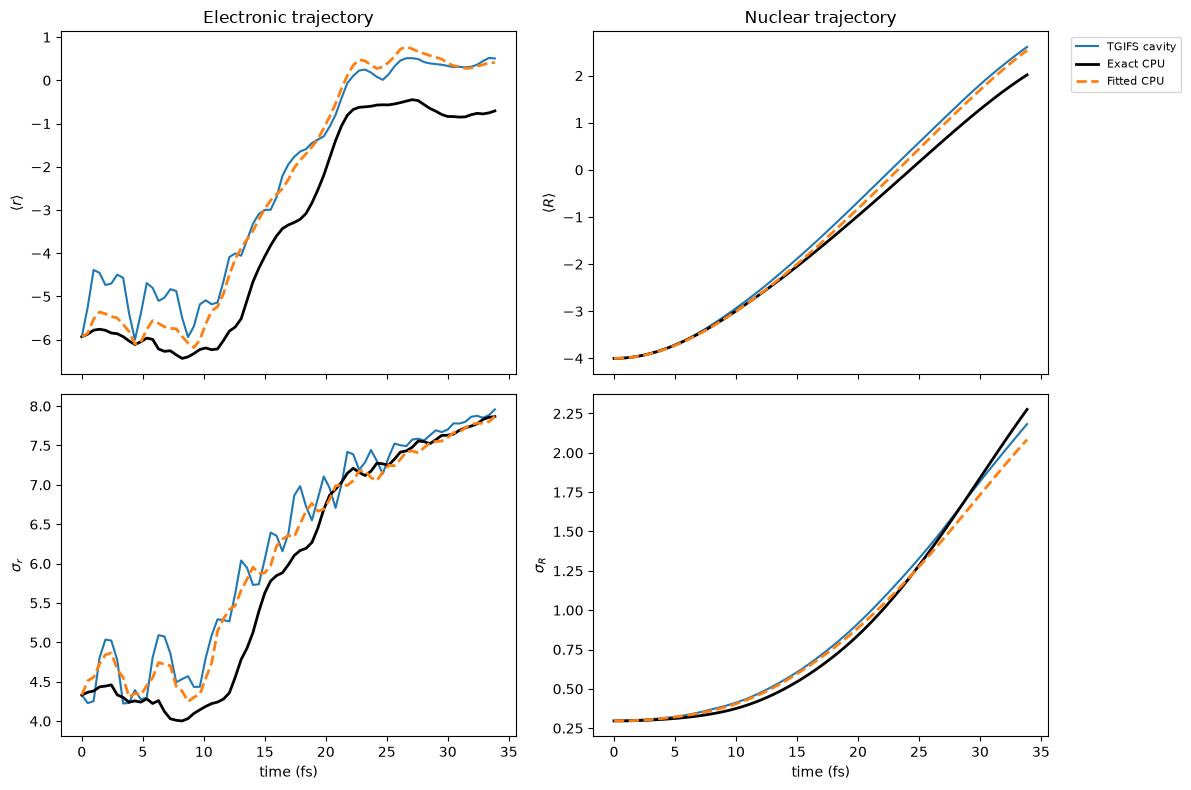

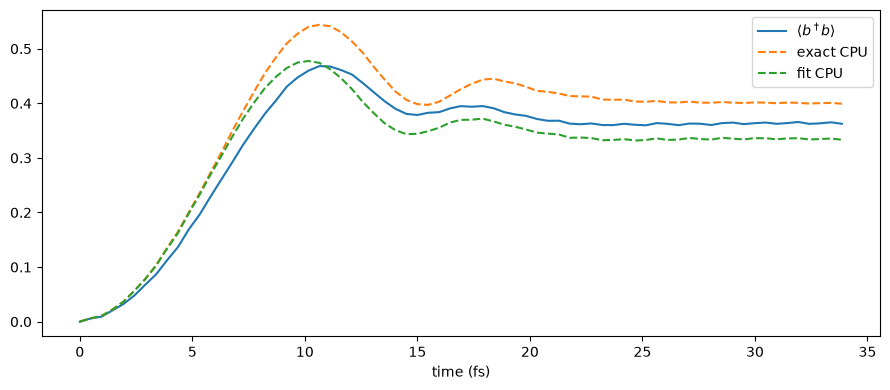

In [16]:
t_fs = times * AU_TIME_TO_FS
qres_disk = qres

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

panels = [
    ('mean_r', r'$\langle r\rangle$', axes[0,0]),
    ('mean_R', r'$\langle R\rangle$', axes[0,1]),
    ('sigma_r', r'$\sigma_r$', axes[1,0]),
    ('sigma_R', r'$\sigma_R$', axes[1,1]),
]
for key,label,ax in panels:
    ax.plot(t_fs, qres_disk[key], '-', label='TGIFS cavity' if include_cavity else 'TGIFS cavity-free')
    ax.set_ylabel(label)

axes[0,0].set_title('Electronic trajectory')
axes[0,1].set_title('Nuclear trajectory')
axes[1,0].set_xlabel('time (fs)')
axes[1,1].set_xlabel('time (fs)')

if RUN_CPU_BASELINES:

    for kind, cpu in cpu_results.items():
        label = (
            "Exact CPU"
            if kind == "exact"
            else "Fitted CPU"
        )

        color = (
            "black"
            if kind == "exact"
            else "tab:orange"
        )

        linestyle = (
            "-"
            if kind == "exact"
            else "--"
        )

        for key, _, ax in panels:

            ax.plot(
                cpu["times"] * AU_TIME_TO_FS,
                cpu[key],
                color=color,
                linestyle=linestyle,
                linewidth=2,
                label=label
            )

axes[0,1].legend(fontsize=8, bbox_to_anchor=(1.04,1), loc='upper left')
plt.tight_layout()
plt.show()

    

if include_cavity:
    fig, ax = plt.subplots(figsize=(9,4))
    ax.plot(t_fs, qres_disk['mean_nph'], label=r'$\langle b^\dagger b\rangle$')
    if RUN_CPU_BASELINES:
        for kind, cpu in cpu_results.items():
            ax.plot(
                cpu["times"] * AU_TIME_TO_FS,
                cpu["mean_nph"],
                "--",
                label=f"{kind} CPU"
            )
    ax.set_xlabel('time (fs)')
    ax.legend()
    plt.tight_layout()
    plt.show()


## Ancilla, cutoff leakage, and sparse density snapshots

`leak_r`, `leak_R`, and `photon_edge_pop` are measured **during** propagation, so no full `psi_t` history is required. To draw a spatial nuclear/electronic density at a saved time, retrieve `qres['psi_t'][k]` and sum `abs(psi)**2` over the other qumode axes. In the cavity case the snapshot has axes `(ph, r, R)`.


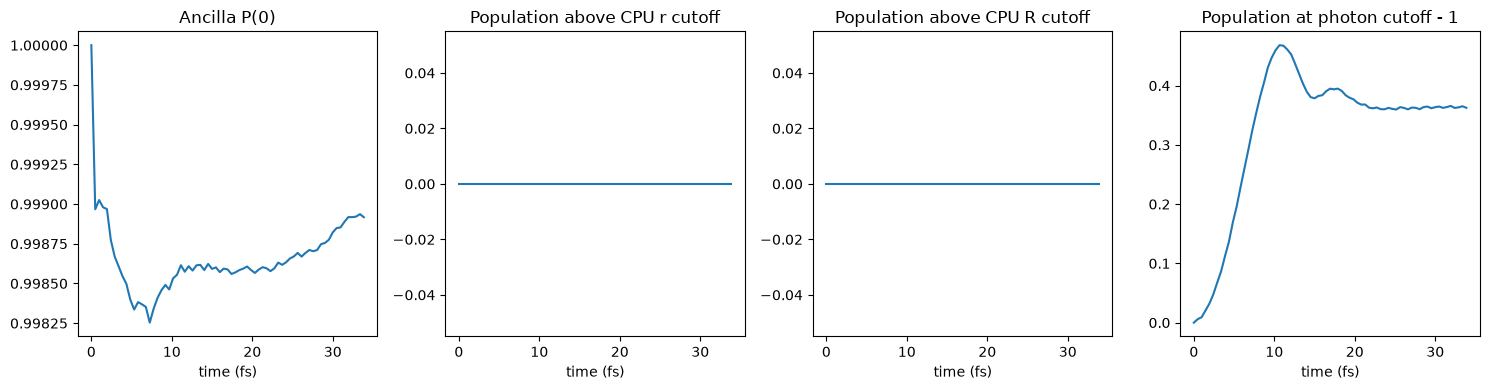

Last snapshot is at output index 70 and time (fs) 33.8643805721998
Reduced Fock population norms: 1.0000000000000002 1.0


In [17]:
fig, axes = plt.subplots(1, 4 if include_cavity else 3, figsize=(15,4))
plot_items = [
    ('p0', 'Ancilla P(0)'),
    ('leak_r', 'Population above CPU r cutoff'),
    ('leak_R', 'Population above CPU R cutoff'),
]
if include_cavity:
    plot_items.append(('photon_edge_pop', 'Population at photon cutoff - 1'))
for ax,(key,label) in zip(axes,plot_items):
    ax.plot(t_fs, qres_disk[key])
    ax.set_title(label)
    ax.set_xlabel('time (fs)')
plt.tight_layout()
plt.show()

# Example: obtain reduced matter densities at the LAST saved wavefunction.
if len(qres_disk['snapshot_indices']):
    k = -1
    saved_index = int(qres_disk['snapshot_indices'][k])
    psi = qres_disk['psi_t'][k]
    prob = np.abs(psi)**2
    if include_cavity:
        density_r = prob.sum(axis=(0,2))
        density_R = prob.sum(axis=(0,1))
    else:
        density_r = prob.sum(axis=1)
        density_R = prob.sum(axis=0)
    print('Last snapshot is at output index', saved_index, 'and time (fs)', t_fs[saved_index])
    print('Reduced Fock population norms:', density_r.sum(), density_R.sum())


cavity_free exact : cpu_exact_no_cavity_a1c74be95fd3e01245142908.npz
cavity_free fitted : cpu_fit_no_cavity_9554f0c724ba837af3f59e1d.npz
cavity_free tgifs : psi_t_tgifs_fullV_gaussian_initc6e7ac0bdd37d588_fitbe365c189d264200_cavityOFF_boxR40_boxr80_NFR14_NFr14_cutr16_cutR128_sub10_save10_last1.npz
cavity exact : cpu_exact_cavity_c83a83dacbcbb75709ab649e.npz
cavity fitted : cpu_fit_cavity_6aff97bdd6b7bba51a305512.npz
cavity tgifs : psi_t_tgifs_fullV_gaussian_initef5ab2cea380710e_fitbe365c189d264200_cavityON_w0.1_lam0.005_cutph2_dse1_boxR40_boxr80_NFR14_NFr14_cutr16_cutR128_sub20_save10_last1.npz


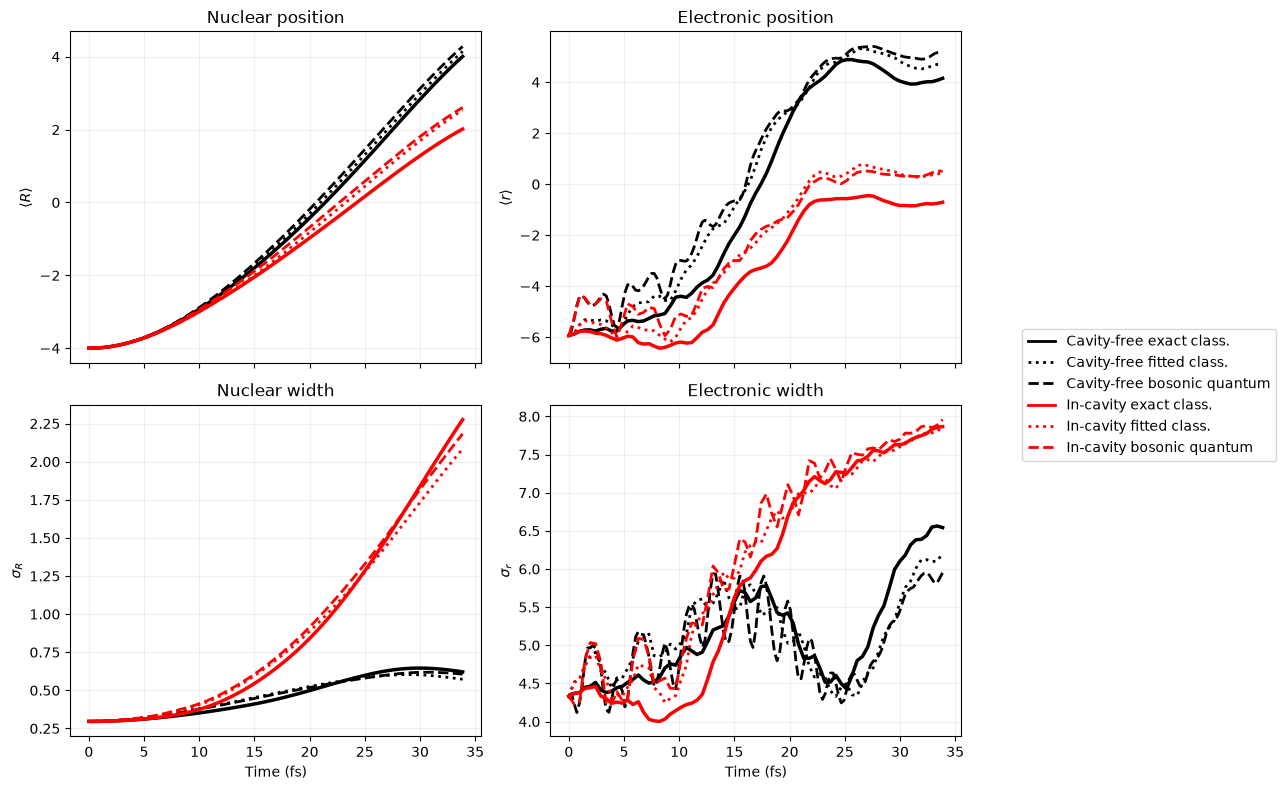

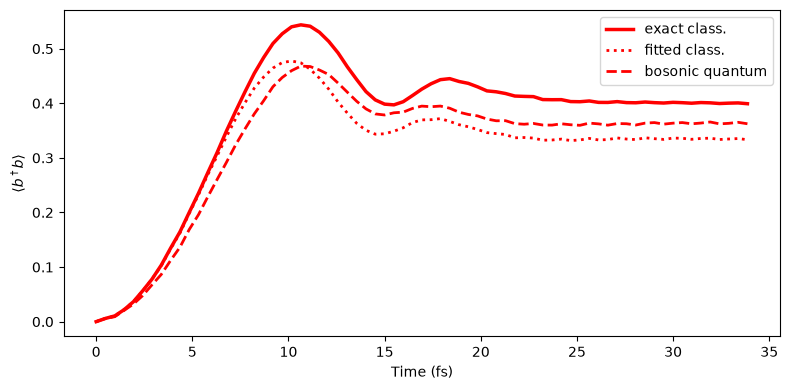

In [33]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.lines import Line2D


RESULTS_DIR = Path("tgifs_full_potential_results")
AU_TIME_TO_FS = 0.024188843265857


# ============================================================
# File patterns
#
# These match the filename conventions of the latest notebook.
# If multiple files match, specify the exact filename instead.
# ============================================================

file_patterns = {

    "cavity_free": {
        "exact": "cpu_exact_no_cavity_*.npz",
        "fitted": "cpu_fit_no_cavity_*.npz",
        "tgifs": "psi_t_tgifs_fullV_*_cavityOFF_*.npz",
    },

    "cavity": {
        "exact": "cpu_exact_cavity_*.npz",
        "fitted": "cpu_fit_cavity_*.npz",
        "tgifs": "psi_t_tgifs_fullV_*_cavityON_*.npz",
    },
}


# ============================================================
# Find files
# ============================================================

def find_file(pattern):

    matches = sorted(RESULTS_DIR.glob(pattern))

    if len(matches) == 0:
        raise FileNotFoundError(
            f"No file matching: {pattern}"
        )

    if len(matches) > 1:
        raise ValueError(
            f"Multiple files match {pattern}:\n"
            + "\n".join(str(p) for p in matches)
            + "\nSpecify the exact filename."
        )

    return matches[0]


# ============================================================
# Load expectation values
# ============================================================

def load_trajectory(path):

    keys = [
        "times",
        "mean_R",
        "mean_r",
        "sigma_R",
        "sigma_r",
    ]

    with np.load(path, allow_pickle=False) as data:

        result = {
            key: data[key]
            for key in keys
        }

        if "mean_nph" in data.files:
            result["mean_nph"] = data["mean_nph"]

    return result


results = {}

for cavity_type, calculations in file_patterns.items():

    results[cavity_type] = {}

    for method, pattern in calculations.items():

        path = find_file(pattern)

        results[cavity_type][method] = load_trajectory(path)

        print(cavity_type, method, ":", path.name)


# ============================================================
# Plot settings
# ============================================================

colors = {
    "cavity_free": "black",
    "cavity": "red",
}

linestyles = {
    "exact": "-",
    "fitted": ":",
    "tgifs": "--",
}

linewidths = {
    "exact": 2.5,
    "fitted": 2.0,
    "tgifs": 2.0,
}

panels = [
    ("mean_R",  r"$\langle R\rangle$"),
    ("mean_r",  r"$\langle r\rangle$"),
    ("sigma_R", r"$\sigma_R$"),
    ("sigma_r", r"$\sigma_r$"),
]


# ============================================================
# Plot trajectories
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True
)

axes = axes.ravel()

for ax, (key, ylabel) in zip(axes, panels):

    for cavity_type in ["cavity_free", "cavity"]:

        for method in ["exact", "fitted", "tgifs"]:

            data = results[cavity_type][method]

            t_fs = data["times"] * AU_TIME_TO_FS

            ax.plot(
                t_fs,
                data[key],
                color=colors[cavity_type],
                linestyle=linestyles[method],
                linewidth=linewidths[method],
            )

    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)


axes[0].set_title("Nuclear position")
axes[1].set_title("Electronic position")
axes[2].set_title("Nuclear width")
axes[3].set_title("Electronic width")

axes[2].set_xlabel("Time (fs)")
axes[3].set_xlabel("Time (fs)")


# ============================================================
# Legend
# ============================================================

legend_handles = []

for cavity_type, color in colors.items():

    for method, linestyle in linestyles.items():

        label = (
            ("In-cavity" if cavity_type == "cavity"
             else "Cavity-free")
            + " "
            + {
                "exact": "exact class.",
                "fitted": "fitted class.",
                "tgifs": "bosonic quantum",
            }[method]
        )

        legend_handles.append(
            Line2D(
                [0], [0],
                color=color,
                linestyle=linestyle,
                linewidth=2,
                label=label
            )
        )


fig.legend(
    handles=legend_handles,
    loc="center left",
    bbox_to_anchor=(0.85, 0.5),
    fontsize=10
)

plt.tight_layout(rect=[0, 0, 0.82, 1])
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))


for method in ["exact", "fitted", "tgifs"]:

    data = results["cavity"][method]

    ax.plot(
        data["times"] * AU_TIME_TO_FS,
        data["mean_nph"],
        color="red",
        linestyle=linestyles[method],
        linewidth=linewidths[method],
        label={
                "exact": "exact class.",
                "fitted": "fitted class.",
                "tgifs": "bosonic quantum",
            }[method]
    )

ax.set_xlabel("Time (fs)")
ax.set_ylabel(r"$\langle b^\dagger b\rangle$")
ax.legend()
plt.tight_layout()
plt.show()

## Implementation notes

- `include_cavity=False` omits the photon register, photon initialization, photon free rotation, photon–matter coupling, and dipole self-energy. The original two-qumode TGIFS/kinetic gates remain.
- `include_cavity=True` adds a photon qumode initially in vacuum. The photon free Hamiltonian is a rotation `cv_r(-omega_alpha*dt, qph[0])`; the bilinear coupling is synthesized from two `cv_sum` gates and shared photon rotations.
- `include_dipole_self_energy=True` includes \(\lambda_\alpha^2(R-r)^2/2\) with Gaussian single-mode quadratic phases and an `XX` cross term. For strict reproduction of Eq. (3), keep it enabled.
- The matter coordinates are always physical: \(r=r_0+l_rX_r\) and \(R=R_0+l_RX_R\), and the new photon coupling uses \(\lambda_\alpha\sqrt{\omega_\alpha}X_\alpha(R-r)\).
- `cached_cv_c_d()` reuses controlled displacement gate objects *within each step circuit*. No cached gates are shared between distinct circuits or cutoffs.
- `RUN_CPU_BASELINES=False` avoids building several dense \((Nr NR)^2\) CPU matrices. Turn it on only when you need the original **cavity-free** CPU reference.
- `qres['mean_r']`, `mean_R`, `sigma_r`, `sigma_R`, `p0`, `mean_nph`, and leakage diagnostics are saved at every output time. `qres['psi_t']` is saved only at `snapshot_indices`; `snapshot_times` identifies those points. Set `N_save=None` and `SAVE_LAST_WAVEFUNCTION=False` to disable snapshots.
- `TOP_N_MODES=None` retains the existing half-lattice weighted-ridge Fourier fit; set a positive `TOP_N_MODES` to select/refit the largest `amplitude` or `force_scale` Fourier terms. Alternatively load a sparse fit using `FIT_SOURCE='csv'` and `FIT_PARAMETER_FILE`.
- The Gaussian identities hold for ideal continuous-variable operators. At finite Fock cutoff (particularly for squeezing and high photon occupation), check the `photon_edge_pop` and matter cutoff diagnostics for truncation artifacts.
- Bosonic Qiskit is required to execute the quantum circuit. This notebook was statically checked and its gate identities tested independently; full Qiskit evolution is not executed in this environment.

- The photonic `cv_sum` gates are local two-qumode dense matrices (not full-system matrices); their cost grows with the product of the two cutoffs. The photon Fock cutoff should still be checked for convergence.
